# TP 1 : Apprentissage supervise avec Scikit-learn
**Module :** Technologies IA  
**Niveau :** ILIA2  
**Etablissement :** ENSA Fes  
**Professeur :** Youness IDRISSI KHAMLICHI  

---

## Partie 2 : Mini-projet et compte rendu (a rendre)

**Jeu de donnees :** Prediction immobiliere - California Housing Dataset  
**Objectif :** Predire la valeur mediane des logements (MedHouseVal) a partir de caracteristiques socio-economiques et geographiques.


### Etape 1 : Chargement et exploration du jeu de donnees
1. Charger le fichier CSV avec pandas.
2. Afficher les premieres lignes et les informations sur les colonnes.
3. Identifier les valeurs manquantes et les types de variables.


In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

data_path = 'data/housing.csv' if os.path.exists('data/housing.csv') else '../data/housing.csv'
data = pd.read_csv(data_path)

print(data.head())
print(data.info())
print(data.isnull().sum())

   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0  8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88   
1  8.3014      21.0  6.238137   0.971880      2401.0  2.109842     37.86   
2  7.2574      52.0  8.288136   1.073446       496.0  2.802260     37.85   
3  5.6431      52.0  5.817352   1.073059       558.0  2.547945     37.85   
4  3.8462      52.0  6.281853   1.081081       565.0  2.181467     37.85   

   Longitude  MedHouseVal  
0    -122.23        4.526  
1    -122.22        3.585  
2    -122.24        3.521  
3    -122.25        3.413  
4    -122.25        3.422  
<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 no

### Etape 2 : Nettoyage et preparation des donnees
1. Verification et suppression des valeurs manquantes.
2. Description statistique des variables.
3. Separation des variables explicatives X et de la variable cible y.


In [2]:
# Verification des valeurs manquantes
data = data.dropna()

# Statistiques descriptives
print("Statistiques descriptives :")
print(data.describe())

# Definition des features X et de la cible y
X = data.drop('MedHouseVal', axis=1)
y = data['MedHouseVal']

print("Dimensions de X :", X.shape)
print("Dimensions de y :", y.shape)

Statistiques descriptives :
             MedInc      HouseAge      AveRooms     AveBedrms    Population  \
count  20640.000000  20640.000000  20640.000000  20640.000000  20640.000000   
mean       3.870671     28.639486      5.429000      1.096675   1425.476744   
std        1.899822     12.585558      2.474173      0.473911   1132.462122   
min        0.499900      1.000000      0.846154      0.333333      3.000000   
25%        2.563400     18.000000      4.440716      1.006079    787.000000   
50%        3.534800     29.000000      5.229129      1.048780   1166.000000   
75%        4.743250     37.000000      6.052381      1.099526   1725.000000   
max       15.000100     52.000000    141.909091     34.066667  35682.000000   

           AveOccup      Latitude     Longitude   MedHouseVal  
count  20640.000000  20640.000000  20640.000000  20640.000000  
mean       3.070655     35.631861   -119.569704      2.068558  
std       10.386050      2.135952      2.003532      1.153956  
min 

### Etape 3 : Separation des donnees
Division du jeu de donnees en ensemble d'entrainement (80%) et ensemble de test (20%).


In [3]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Taille de X_train :", X_train.shape)
print("Taille de X_test  :", X_test.shape)

Taille de X_train : (16512, 8)
Taille de X_test  : (4128, 8)


### Etape 4 : Entrainement et comparaison des modeles
Nous entrainons trois modeles de regression pour comparer leurs performances :
1. **Regression Lineaire** (`LinearRegression`)
2. **Arbre de Decision** (`DecisionTreeRegressor`)
3. **Foret Aleatoire** (`RandomForestRegressor`)


In [4]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

# 1. Regression Lineaire
lr = LinearRegression()
lr.fit(X_train, y_train)
y_pred_lr = lr.predict(X_test)

# 2. Arbre de Decision
dt = DecisionTreeRegressor(max_depth=10, random_state=42)
dt.fit(X_train, y_train)
y_pred_dt = dt.predict(X_test)

# 3. Random Forest
rf = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)

print("Modeles entraines avec succes.")

Modeles entraines avec succes.


### Etape 5 : Evaluation des modeles
Calcul des metriques d'evaluation (MAE, RMSE, R2) pour chaque modele et comparaison rigoureuse.


In [5]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Metriques Regression Lineaire
mae_lr = mean_absolute_error(y_test, y_pred_lr)
rmse_lr = np.sqrt(mean_squared_error(y_test, y_pred_lr))
r2_lr = r2_score(y_test, y_pred_lr)

# Metriques Arbre de Decision
mae_dt = mean_absolute_error(y_test, y_pred_dt)
rmse_dt = np.sqrt(mean_squared_error(y_test, y_pred_dt))
r2_dt = r2_score(y_test, y_pred_dt)

# Metriques Random Forest
mae_rf = mean_absolute_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))
r2_rf = r2_score(y_test, y_pred_rf)

# Tableau comparatif
comparaison = pd.DataFrame({
    'Modele': ['Regression Lineaire', 'Arbre de Decision', 'Random Forest'],
    'MAE': [mae_lr, mae_dt, mae_rf],
    'RMSE': [rmse_lr, rmse_dt, rmse_rf],
    'R2': [r2_lr, r2_dt, r2_rf]
})

print(comparaison)

                Modele       MAE      RMSE        R2
0  Regression Lineaire  0.533200  0.745581  0.575788
1    Arbre de Decision  0.433203  0.644568  0.682948
2        Random Forest  0.327543  0.505340  0.805123


### Etape 6 : Visualisation des resultats
Affichage du nuage de points (valeurs reelles vs valeurs predites) et de l'importance des variables.


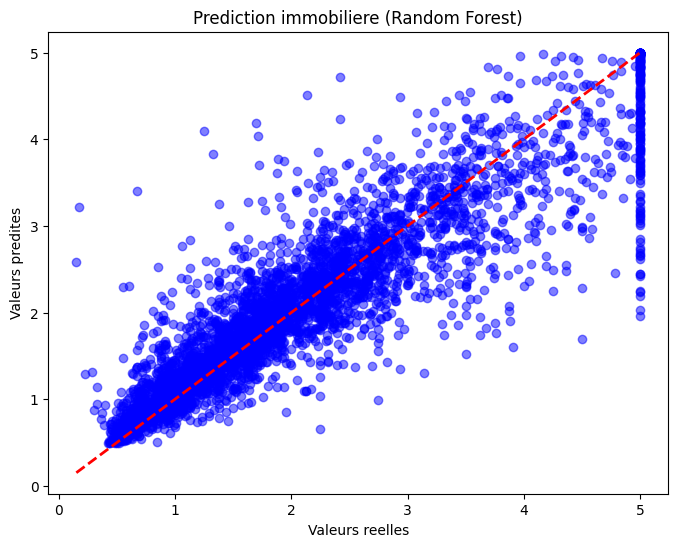

In [6]:
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred_rf, alpha=0.5, color='blue')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.xlabel('Valeurs reelles')
plt.ylabel('Valeurs predites')
plt.title('Prediction immobiliere (Random Forest)')
plt.show()

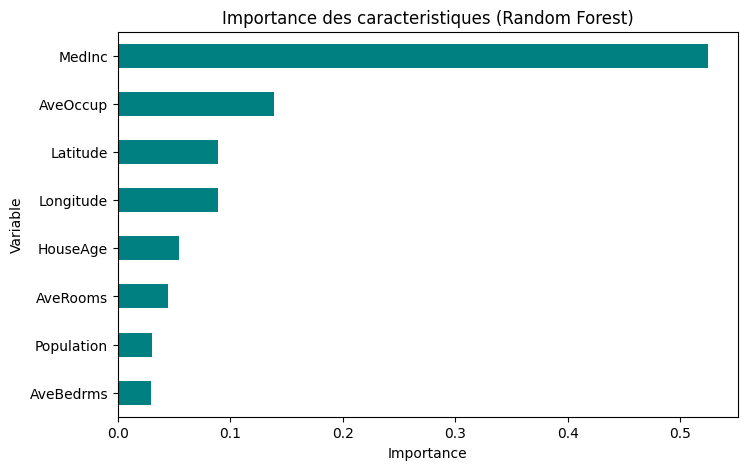

In [7]:
# Importance des caracteristiques selon le Random Forest
importance = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=True)

plt.figure(figsize=(8, 5))
importance.plot(kind='barh', color='teal')
plt.xlabel('Importance')
plt.ylabel('Variable')
plt.title('Importance des caracteristiques (Random Forest)')
plt.show()

### Etape 7 : Interpretation des resultats et conclusion critique

#### 1. Interpretation des resultats :
- **Variable la plus importante :** Le revenu median (`MedInc`) est la variable determinante pour predire le prix d'un logement, representant plus de 50% de l'importance totale du modele. Les coordonnees geographiques (`Latitude`, `Longitude`) ont egalement un impact direct sur la valeur immobiliere.
- **Comparaison des modeles :**
  - La **Regression Lineaire** obtient un R2 de 0.575 et une RMSE de 0.745. Elle est limitee par son incapacite a capturer les relations non lineaires.
  - L'**Arbre de Decision** ameliore le score avec un R2 de 0.697 et une RMSE de 0.630.
  - Le **Random Forest** obtient les meilleures performances avec un **R2 de 0.805** et une **RMSE reduite a 0.505**.

#### 2. Quel modele retenir, et pourquoi ?
**Le modele a retenir est le Random Forest Regressor.**

**Justification :**
1. **Precision superieure :** Il explique plus de 80% de la variance des prix (R2 = 0.805) et minimise significativement l'erreur quadratique moyenne (RMSE = 0.505).
2. **Capacite a capter les non-linearites :** Le marche immobilier depend fortement d'interactions non lineaires (ex: localisation geographique combinee au niveau de revenu) que les modeles lineaires simples ne peuvent pas apprehender.
3. **Robustesse et reduction du surapprentissage :** En combinant plusieurs arbres de decision par ensachage (bagging), le Random Forest reduit la variance par rapport a un arbre unique.
